# Six Degrees of MoMA: 04 Analysis

This notebook reads the saved results of `02_baselines` and `03_gnn` and produces the report's
tables and figures. It trains nothing, so it runs in about a minute on any machine.

1. **Main results**: every model on the curated test exhibitions, mean ± std over seeds.
2. **Curator ablations**: paired bootstrap CIs for the comparisons the research question rests on.
3. **Subgroups**: which artists curator information helps (established vs emerging, gender,
   nationality).
4. **Cold start**: ranking artists who make their MoMA debut.
5. **Limitations**: uncurated exhibitions and curator coverage over time.
6. **Case studies**: the artists whose rank improves most with curators, and why.

Figures and tables go to `results/analysis/`.

In [1]:
# Installs anything missing. Colab already has torch, pandas, scikit-learn and matplotlib.
import importlib.util, subprocess, sys

REQUIRED = {"torch": "torch", "torch_geometric": "torch_geometric", "pyarrow": "pyarrow",
            "sentence_transformers": "sentence-transformers", "scipy": "scipy",
            "sklearn": "scikit-learn", "matplotlib": "matplotlib"}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

In [2]:
from pathlib import Path

# On Colab, set USE_DRIVE = True to keep data and results across sessions.
USE_DRIVE = False
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/moma-project")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
RESULTS_DIR = ROOT / "results"
for d in [RAW_DIR, PROCESSED_DIR, RESULTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CFG = {
    # Raw ExhibitionRole values mapped onto node roles; everything else is "other".
    # Institutions listed with a curator role are treated as "other" (organizers).
    "roles": {"artist": ["Artist"], "curator": ["Curator"]},
    "features": {"title_encoder": "minilm",   # minilm | tfidf
                 "title_dim": 32, "top_nationalities": 12,
                 "collection": True},     # MoMA Collection acquisition counts per artist
    "split": {
        "cutoffs": [1950, 1960, 1970, 1980],
        "val_years": 5,       # val targets:  [T - val_years, T)
        "test_years": 10,     # test targets: [T, T + test_years)
        "train_window": 5,    # rolling training targets: [t, t + train_window)
        "train_start": 1932,  # earliest pseudo-cutoff for training snapshots
    },
    "eval": {"ks": [10, 20, 50], "primary_metric": "map@20"},
    "baselines": {
        "recency_tau": 10.0,
        "node2vec": {"dim": 64, "walk_length": 20, "walks_per_node": 10, "window": 4,
                     "p": 1.0, "q": 1.0, "epochs": 2, "num_neg": 5},
    },
    "model": {
        "name": "rgcn",           # rgcn | heteroconv | hgt | sage | gat | mlp
        "curator_mode": "full",   # full | none | shuffled
        "hidden": 64, "layers": 3, "dropout": 0.2, "lr": 0.005, "weight_decay": 1e-4,
        "epochs": 300, "eval_every": 5, "patience": 10,   # patience in evaluation rounds
        "loss": "bpr",            # bpr | bce
        "num_neg": 20,
        "curator_ids": True,      # learned embedding per curator (heterogeneous models)
        "max_group": None,        # subsample group shows above this size (homogeneous graph)
    },
    "seeds": [0, 1, 2, 3, 4],
}

## Core: data loading and cleaning

The CSV has one row per (exhibition, constituent, role) and is cp1252-encoded. MoMA's
collection data adds one row per acquired artwork; only the artist and acquisition date are kept.

- **Exhibitions** are keyed on (number, title, begin date). ExhibitionID is missing for about 430 rows, and
  the number "No#" covers about 50 different exhibitions. `exh_id` is the chronological index.
- **Constituents** without a ConstituentID are keyed by display name.
- **Roles**: `artist`, `curator` (an individual with `ExhibitionRole == "Curator"`) or `other`.

In [3]:
import copy, json, re, time, urllib.request
from dataclasses import dataclass, replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_URL = "https://raw.githubusercontent.com/MuseumofModernArt/exhibitions/master/"
EXHIBITIONS_FILE = "MoMAExhibitions1929to1989.csv"
# MoMA's collection data (73 MB, stored with Git LFS, hence the media URL).
COLLECTION_URL = "https://media.githubusercontent.com/media/MuseumofModernArt/collection/main/"
COLLECTION_FILE = "Artworks.csv"
TABLES = ["exhibitions", "constituents", "participation", "acquisitions"]


def download(raw_dir, force=False):
    for url, name in [(BASE_URL, EXHIBITIONS_FILE), (COLLECTION_URL, COLLECTION_FILE)]:
        dest = raw_dir / name
        if force or not dest.exists():
            print(f"downloading {name}")
            urllib.request.urlretrieve(url + name, dest)


def load_raw(raw_dir):
    return pd.read_csv(raw_dir / EXHIBITIONS_FILE, encoding="cp1252", dtype=str)


def build_exhibitions(raw):
    ex = raw.drop_duplicates("exh_key")[[
        "exh_key", "ExhibitionID", "ExhibitionNumber", "ExhibitionTitle",
        "ExhibitionBeginDate", "ExhibitionEndDate", "ExhibitionSortOrder", "ExhibitionURL",
    ]].copy()
    ex["begin"] = pd.to_datetime(ex["ExhibitionBeginDate"], format="%m/%d/%Y")
    ex["end"] = pd.to_datetime(ex["ExhibitionEndDate"], format="%m/%d/%Y")
    ex["sort_order"] = pd.to_numeric(ex["ExhibitionSortOrder"], errors="coerce")
    ex = ex.sort_values(["begin", "sort_order", "exh_key"]).reset_index(drop=True)
    ex["exh_id"] = np.arange(len(ex))
    ex["year"] = ex["begin"].dt.year + (ex["begin"].dt.day_of_year - 1) / 365.25
    duration = (ex["end"] - ex["begin"]).dt.days
    ex["duration_days"] = duration.where(duration >= 0)
    return ex.rename(columns={
        "ExhibitionID": "source_id", "ExhibitionNumber": "number",
        "ExhibitionTitle": "title", "ExhibitionURL": "url",
    })[["exh_id", "exh_key", "source_id", "number", "title", "begin", "end", "year",
        "duration_days", "url"]]


def build_constituents(rows):
    def first_valid(s):
        s = s.dropna()
        return s.iloc[0] if len(s) else None

    cols = {
        "DisplayName": "name", "ConstituentType": "type", "Nationality": "nationality",
        "Gender": "gender", "ConstituentBeginDate": "birth_year",
        "ConstituentEndDate": "death_year", "WikidataID": "wikidata", "ULANID": "ulan",
    }
    con = rows.groupby("cid")[list(cols)].agg(first_valid).rename(columns=cols).reset_index()
    con["gender"] = con["gender"].str.lower().fillna("unknown")
    nat = con["nationality"]
    con["nationality"] = nat.where(nat != "Nationality unknown").fillna("unknown")
    con["type"] = con["type"].fillna("unknown")
    for col in ["birth_year", "death_year"]:
        year = pd.to_numeric(con[col], errors="coerce")
        con[col] = year.where(year > 0)
    return con


def build_participation(rows, roles):
    raw_role = rows["ExhibitionRole"]
    role = pd.Series("other", index=rows.index)
    role[raw_role.isin(roles["artist"])] = "artist"
    is_curator = raw_role.isin(roles["curator"]) & (rows["ConstituentType"] != "Institution")
    role[is_curator] = "curator"
    part = pd.DataFrame({
        "exh_id": rows["exh_id"].values,
        "cid": rows["cid"].values,
        "role": role.values,
        "raw_role": raw_role.values,
        "press_role": rows["ExhibitionRoleinPressRelease"].values,
    })
    return part.drop_duplicates(["exh_id", "cid", "role"]).reset_index(drop=True)


def clean(raw, roles):
    raw = raw.copy()
    raw["exh_key"] = (raw["ExhibitionNumber"].fillna("") + "|" + raw["ExhibitionTitle"].fillna("")
                      + "|" + raw["ExhibitionBeginDate"].fillna(""))
    exhibitions = build_exhibitions(raw)
    raw["exh_id"] = raw["exh_key"].map(exhibitions.set_index("exh_key")["exh_id"])

    # Rows with no role and no constituent only record that an exhibition happened.
    rows = raw[raw["ExhibitionRole"].notna() & raw["DisplayName"].notna()].copy()
    rows["cid"] = ("moma:" + rows["ConstituentID"]).fillna("name:" + rows["DisplayName"].str.strip())
    constituents = build_constituents(rows)
    participation = build_participation(rows, roles)

    has_curator = participation.loc[participation["role"] == "curator", "exh_id"].unique()
    exhibitions["has_curator"] = exhibitions["exh_id"].isin(has_curator)
    return {"exhibitions": exhibitions, "constituents": constituents,
            "participation": participation}


def load_acquisitions(raw_dir):
    """One row per (artwork, artist) acquired by MoMA, with the acquisition date. Artists are
    keyed like exhibition constituents ("moma:<ConstituentID>"), which is the same id space."""
    works = pd.read_csv(raw_dir / COLLECTION_FILE, dtype=str,
                        usecols=["ObjectID", "ConstituentID", "DateAcquired"])
    works["acquired"] = pd.to_datetime(works["DateAcquired"], errors="coerce")
    works = works.dropna(subset=["ConstituentID", "acquired"])
    works = works.assign(cid=works["ConstituentID"].str.split(",")).explode("cid")
    works["cid"] = "moma:" + works["cid"].str.strip()
    return works[["cid", "ObjectID", "acquired"]].rename(columns={"ObjectID": "object_id"}) \
        .drop_duplicates().reset_index(drop=True)


def load_tables(force=False):
    """Cleaned tables from data/processed, rebuilding them from the raw CSV if needed."""
    if not force and all((PROCESSED_DIR / f"{n}.parquet").exists() for n in TABLES):
        return {n: pd.read_parquet(PROCESSED_DIR / f"{n}.parquet") for n in TABLES}
    download(RAW_DIR)
    tables = clean(load_raw(RAW_DIR), CFG["roles"])
    tables["acquisitions"] = load_acquisitions(RAW_DIR)
    for name, df in tables.items():
        df.to_parquet(PROCESSED_DIR / f"{name}.parquet", index=False)
    return tables

### Integer-indexed dataset

Artists and curators have separate node index spaces. A person who both exhibited and curated
appears once in each; both keep `cid` so they can be merged back into one person when needed.

`with_shuffled_curators` is the shuffle ablation. It permutes curator→exhibition assignments
within each decade, so every curator keeps their number of exhibitions and every exhibition
keeps its number of curators.

In [4]:
@dataclass
class MomaData:
    exhibitions: pd.DataFrame    # indexed by exh_id (chronological)
    artists: pd.DataFrame        # indexed by artist node id
    curators: pd.DataFrame       # indexed by curator node id
    artist_edges: pd.DataFrame   # columns exh_id, artist
    curator_edges: pd.DataFrame  # columns exh_id, curator
    acquisitions: pd.DataFrame   # columns artist, year: collection artworks by acquisition date

    @classmethod
    def from_tables(cls, tables):
        ex = tables["exhibitions"].set_index("exh_id", drop=False).sort_index()
        con = tables["constituents"].set_index("cid")
        part = tables["participation"]

        def role_nodes(role):
            edges = part[part["role"] == role][["exh_id", "cid"]]
            cids = np.sort(edges["cid"].unique())
            nodes = con.loc[cids].reset_index()
            node_of = pd.Series(np.arange(len(cids)), index=cids)
            edges = pd.DataFrame({"exh_id": edges["exh_id"].to_numpy(),
                                  role: node_of.loc[edges["cid"]].to_numpy()})
            return nodes, edges.sort_values(["exh_id", role]).reset_index(drop=True)

        artists, artist_edges = role_nodes("artist")
        curators, curator_edges = role_nodes("curator")

        acq = tables["acquisitions"]
        artist_of = pd.Series(artists.index, index=artists["cid"])
        acq = acq[acq["cid"].isin(artist_of.index)]
        date = acq["acquired"].dt
        acquisitions = pd.DataFrame({
            "artist": artist_of.loc[acq["cid"]].to_numpy(),
            "year": (date.year + (date.day_of_year - 1) / 365.25).to_numpy(),
        }).sort_values("year", ignore_index=True)
        return cls(ex, artists, curators, artist_edges, curator_edges, acquisitions)

    @property
    def num_artists(self):
        return len(self.artists)

    @property
    def num_curators(self):
        return len(self.curators)

    @property
    def num_exhibitions(self):
        return len(self.exhibitions)

    def with_shuffled_curators(self, seed):
        rng = np.random.default_rng(seed)
        edges = self.curator_edges.copy()
        decade = (self.exhibitions.loc[edges["exh_id"], "begin"].dt.year // 10).to_numpy()
        exh = edges["exh_id"].to_numpy().copy()
        for d in np.unique(decade):
            idx = np.flatnonzero(decade == d)
            exh[idx] = exh[rng.permutation(idx)]
        edges["exh_id"] = exh
        # A permutation can rarely pair a curator with the same exhibition twice.
        edges = edges.drop_duplicates().sort_values(["exh_id", "curator"]).reset_index(drop=True)
        return replace(self, curator_edges=edges)

## Core: temporal snapshots

A snapshot fixes a history cutoff and a set of target exhibitions after it. A model may see:

- every artist and curator edge of exhibitions that began before `history_end`;
- the curator edges and metadata of the target exhibitions.

It must rank the `candidates` (artists with at least one exhibition in the history) for each
target. The targets' artist edges are labels only.

For a cutoff year T:

| split | history | targets |
|---|---|---|
| train (rolling) | before t, for each t < T−5 | [t, min(t+5, T−5)) |
| validation | before T−5 | [T−5, T) |
| test | before T | [T, T+10) |

Rolling training snapshots have the same form as the test task, and the model never sees edges
from after its own targets.

`cold_start_snapshot` keeps a snapshot's targets but swaps the candidates for artists who make
their MoMA debut in the window. It is evaluated separately, because no history-based score can
rank those artists.

In [5]:
@dataclass
class Snapshot:
    history_end: pd.Timestamp
    targets: np.ndarray         # exh_ids, chronological
    hist_artist: np.ndarray     # [2, E] (exh_id, artist) for history exhibitions
    hist_curator: np.ndarray    # [2, E] (exh_id, curator) for history exhibitions
    target_curator: np.ndarray  # [2, E] (exh_id, curator) for target exhibitions
    candidates: np.ndarray      # artist ids with >=1 history exhibition, sorted
    positives: dict             # target exh_id -> all participating artist ids
    has_curator: np.ndarray     # per target: recorded curator in the original data

    @property
    def ref_year(self):
        ts = self.history_end
        return ts.year + (ts.day_of_year - 1) / 365.25

    @property
    def curator_edges(self):
        return np.concatenate([self.hist_curator, self.target_curator], axis=1)

    def label_matrix(self):
        """Boolean [num_targets, num_candidates]; True where the candidate exhibited."""
        labels = np.zeros((len(self.targets), len(self.candidates)), dtype=bool)
        for i, e in enumerate(self.targets):
            labels[i] = np.isin(self.candidates, self.positives[e], assume_unique=True)
        return labels


def _edges(df, col, mask):
    sub = df[mask]
    return np.stack([sub["exh_id"].to_numpy(), sub[col].to_numpy()]).astype(np.int64)


def make_snapshot(data, target_start, target_end, history_end=None):
    target_start, target_end = pd.Timestamp(target_start), pd.Timestamp(target_end)
    history_end = pd.Timestamp(history_end) if history_end is not None else target_start
    assert history_end <= target_start

    ex = data.exhibitions
    hist_ids = ex.index[ex["begin"] < history_end].to_numpy()
    targets = ex.index[(ex["begin"] >= target_start) & (ex["begin"] < target_end)].to_numpy().copy()

    ae, ce = data.artist_edges, data.curator_edges
    hist_artist = _edges(ae, "artist", ae["exh_id"].isin(hist_ids))
    hist_curator = _edges(ce, "curator", ce["exh_id"].isin(hist_ids))
    target_curator = _edges(ce, "curator", ce["exh_id"].isin(targets))

    target_artists = ae[ae["exh_id"].isin(targets)].groupby("exh_id")["artist"]
    positives = {e: np.array([], dtype=np.int64) for e in targets}
    positives.update({e: g.to_numpy() for e, g in target_artists})

    return Snapshot(
        history_end=history_end,
        targets=targets,
        hist_artist=hist_artist,
        hist_curator=hist_curator,
        target_curator=target_curator,
        candidates=np.unique(hist_artist[1]),
        positives=positives,
        has_curator=ex.loc[targets, "has_curator"].to_numpy(),
    )


def cold_start_snapshot(data, snap):
    """The same targets, ranked against the window's debuting artists instead of returning ones.

    Candidates are artists with no history who exhibit in at least one target. Knowing who debuts
    somewhere in the window is an oracle assumption; the task is to predict where."""
    appearing = np.concatenate([np.array([], dtype=np.int64), *snap.positives.values()])
    return replace(snap, candidates=np.setdiff1d(appearing, snap.candidates))


def year_start(year):
    return pd.Timestamp(year=int(year), month=1, day=1)


def eval_snapshots(data, cutoff, split_cfg):
    val_start = cutoff - split_cfg["val_years"]
    val = make_snapshot(data, year_start(val_start), year_start(cutoff))
    test = make_snapshot(data, year_start(cutoff), year_start(cutoff + split_cfg["test_years"]))
    return val, test


def train_snapshots(data, cutoff, split_cfg):
    val_start = cutoff - split_cfg["val_years"]
    snaps = []
    for t in range(split_cfg["train_start"], val_start):
        end = min(t + split_cfg["train_window"], val_start)
        snap = make_snapshot(data, year_start(t), year_start(end))
        if len(snap.targets) and len(snap.candidates):
            snaps.append(snap)
    return snaps

## Core: metrics and evaluation protocol

Every model is a scorer with `score(snapshot) -> [num_targets, num_candidates]`, so candidate
pools, tie-breaking and metrics are identical across baselines and GNNs. Ties are broken at
random, not by candidate order.

The **primary subset** is test exhibitions that have a recorded curator and at least one returning
artist. Exhibitions whose artists are all MoMA debuts are kept with `n_pos_in_pool = 0` for the
cold-start analysis.

In [6]:
from sklearn.metrics import average_precision_score, roc_auc_score


def rank_order(scores, rng):
    """Indices sorted by descending score, ties broken uniformly at random."""
    return np.lexsort((rng.random(len(scores)), -scores))


def ranking_metrics(scores, labels, ks, rng):
    """Per-query metrics for one exhibition. `labels` is a boolean vector with >=1 True."""
    order = rank_order(scores, rng)
    rel = labels[order].astype(float)
    n_pos = rel.sum()
    hits = np.cumsum(rel)
    precision_at = hits / np.arange(1, len(rel) + 1)
    discounts = 1.0 / np.log2(np.arange(2, len(rel) + 2))

    out = {}
    for k in ks:
        out[f"recall@{k}"] = hits[min(k, len(rel)) - 1] / n_pos
        out[f"map@{k}"] = (precision_at[:k] * rel[:k]).sum() / min(n_pos, k)
        ideal = discounts[:int(min(n_pos, k))].sum()
        out[f"ndcg@{k}"] = (discounts[:k] * rel[:k]).sum() / ideal
    if n_pos < len(rel):
        out["auc"] = roc_auc_score(labels, scores)
        out["ap"] = average_precision_score(labels, scores)
    else:
        out["auc"] = out["ap"] = np.nan

    ranks = np.empty(len(rel), dtype=np.int64)
    ranks[order] = np.arange(1, len(rel) + 1)
    return out, ranks[labels]


def evaluate(scorer, snap, ks, seed=0):
    """Returns (per-exhibition metrics, per-positive ranks)."""
    rng = np.random.default_rng(seed)
    scores = np.asarray(scorer.score(snap), dtype=np.float64)
    assert scores.shape == (len(snap.targets), len(snap.candidates))
    labels = snap.label_matrix()

    rows, rank_rows = [], []
    for i, e in enumerate(snap.targets):
        n_in_pool = int(labels[i].sum())
        row = {"exh_id": e, "has_curator": bool(snap.has_curator[i]),
               "n_pos": len(snap.positives[e]), "n_pos_in_pool": n_in_pool,
               "n_candidates": len(snap.candidates)}
        if n_in_pool:
            metrics, ranks = ranking_metrics(scores[i], labels[i], ks, rng)
            row.update(metrics)
            rank_rows.append(pd.DataFrame({
                "exh_id": e, "artist": snap.candidates[labels[i]], "rank": ranks,
                "n_candidates": len(snap.candidates)}))
        rows.append(row)
    per_exh = pd.DataFrame(rows)
    ranks = pd.concat(rank_rows, ignore_index=True) if rank_rows else pd.DataFrame()
    return per_exh, ranks


def metric_columns(per_exh):
    return [c for c in per_exh.columns if "@" in c or c in ("auc", "ap")]


def summarize(per_exh):
    """Mean metrics on the curated subset and on all exhibitions with >=1 returning artist."""
    scored = per_exh[per_exh["n_pos_in_pool"] > 0]
    cols = metric_columns(per_exh)
    return {name: {"n_exhibitions": len(subset), **subset[cols].mean().to_dict()}
            for name, subset in [("curated", scored[scored["has_curator"]]), ("all", scored)]}


def paired_bootstrap(a, b, n_boot=1000, seed=0, ci=0.95):
    """CI for mean(a - b), resampling the paired units (test exhibitions)."""
    diff = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    diff = diff[~np.isnan(diff)]
    rng = np.random.default_rng(seed)
    means = diff[rng.integers(0, len(diff), size=(n_boot, len(diff)))].mean(axis=1)
    lo, hi = np.quantile(means, [(1 - ci) / 2, 1 - (1 - ci) / 2])
    return {"mean_diff": diff.mean(), "ci_low": lo, "ci_high": hi, "n": len(diff),
            "p_le_0": float((means <= 0).mean())}


RESULT_FILE = re.compile(r"(?P<tag>.+)_T(?P<cutoff>\d{4})(?:_s(?P<seed>\d+))?_"
                         r"(?P<kind>per_exh|ranks|cold_per_exh|cold_ranks)\.csv")


def result_files(tag, cutoff, kind="per_exh"):
    """Saved result files of one run tag: one per seed for GNNs, a single file for baselines.
    `kind` is per_exh or ranks, prefixed with cold_ for the cold-start evaluation."""
    files = []
    for d in ["gnn", "baselines"]:
        for f in sorted((RESULTS_DIR / d).glob(f"{tag}_T{cutoff}*.csv")):
            m = RESULT_FILE.fullmatch(f.name)
            if m and m["tag"] == tag and m["kind"] == kind:
                files.append(f)
    return files


def load_per_exh(tag, cutoff, kind="per_exh"):
    """Saved per-exhibition results (averaged over seeds) on the curated subset."""
    files = result_files(tag, cutoff, kind)
    if not files:
        return None, 0
    runs = pd.concat([pd.read_csv(f) for f in files])
    scored = runs[(runs["n_pos_in_pool"] > 0) & runs["has_curator"]]
    return scored.groupby("exh_id").mean(numeric_only=True), len(files)


def compare_runs(a, b, metric="map@20", cutoffs=None, n_boot=1000, kind="per_exh"):
    """Paired bootstrap of A - B over curated test exhibitions, per cutoff.

    Tags: baselines by name (e.g. "curator_collab"); GNNs as "{model}_{mode}" (e.g. "rgcn_none").
    """
    rows = []
    for cutoff in cutoffs or CFG["split"]["cutoffs"]:
        (ra, na), (rb, nb) = load_per_exh(a, cutoff, kind), load_per_exh(b, cutoff, kind)
        if ra is None or rb is None:
            continue
        joined = ra[[metric]].merge(rb[[metric]], left_index=True, right_index=True,
                                    suffixes=("_a", "_b"))
        res = paired_bootstrap(joined[f"{metric}_a"], joined[f"{metric}_b"], n_boot=n_boot)
        rows.append({"cutoff": cutoff, "seeds_a": na, "seeds_b": nb,
                     a: joined[f"{metric}_a"].mean(), b: joined[f"{metric}_b"].mean(), **res})
    return pd.DataFrame(rows)

## Load data and results

In [7]:
tables = load_tables()
data = MomaData.from_tables(tables)
OUT = RESULTS_DIR / "analysis"
OUT.mkdir(exist_ok=True)
CUTOFFS = CFG["split"]["cutoffs"]

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984",
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "figure.facecolor": "white",
})

# Display names, in table order.
LABELS = {
    "random": "Random", "popularity": "Popularity", "recency_popularity": "Recency popularity",
    "collection_popularity": "Collection popularity",
    "common_neighbors": "Common neighbors", "adamic_adar": "Adamic–Adar", "node2vec": "Node2Vec",
    "curator_collab": "Curator collaboration",
    "demographic_popularity": "Demographic popularity", "curator_profile": "Curator profile",
    "mlp_none": "MLP, features only",
    "sage_none": "GraphSAGE, artist graph", "gat_none": "GAT, artist graph",
    "rgcn_none": "R-GCN, no curators", "heteroconv_none": "HeteroConv, no curators",
    "rgcn_shuffled": "R-GCN, shuffled curators",
    "rgcn_full": "R-GCN", "heteroconv_full": "HeteroConv", "hgt_full": "HGT",
}
FAMILY_COLORS = {"heuristic baseline": "#8a8984", "learned, no curator information": "#eb6834",
                 "GNN, shuffled curators": "#1baf7a", "GNN, real curators": "#2a78d6"}


def family(tag):
    if not tag.endswith(("_full", "_none", "_shuffled")):
        return "heuristic baseline"
    if tag.endswith("_none"):
        return "learned, no curator information"
    return "GNN, shuffled curators" if tag.endswith("_shuffled") else "GNN, real curators"


def model_order(models):
    models = list(models)
    return [m for m in LABELS if m in models] + sorted(set(models) - set(LABELS))


def collect_runs():
    """One row per saved result file and exhibition subset, with mean metrics."""
    rows = []
    for d in ["baselines", "gnn"]:
        for f in sorted((RESULTS_DIR / d).glob("*.csv")):
            m = RESULT_FILE.fullmatch(f.name)
            if not m or m["kind"] not in ("per_exh", "cold_per_exh"):
                continue
            per_exh = pd.read_csv(f)
            scored = per_exh[per_exh["n_pos_in_pool"] > 0]
            cols = metric_columns(per_exh)
            for subset, sub in [("curated", scored[scored["has_curator"]]),
                                ("uncurated", scored[~scored["has_curator"]]), ("all", scored)]:
                rows.append({"model": m["tag"], "cutoff": int(m["cutoff"]),
                             "seed": int(m["seed"] or 0),
                             "eval": "cold" if m["kind"].startswith("cold") else "main",
                             "subset": subset, "n_exhibitions": len(sub), **sub[cols].mean()})
    return pd.DataFrame(rows)


runs = collect_runs()
print(f"{len(runs)} result rows from {runs['model'].nunique()} models")
runs.groupby(["eval", "model"])["seed"].nunique().unstack(0).loc[model_order(runs["model"].unique())]

936 result rows from 19 models


eval,cold,main
model,,
random,1.0,1.0
popularity,NaN,1.0
recency_popularity,NaN,1.0
collection_popularity,1.0,1.0
common_neighbors,NaN,1.0
adamic_adar,NaN,1.0
node2vec,NaN,1.0
curator_collab,NaN,1.0
demographic_popularity,1.0,NaN


## 1. Main results

MAP@20 on curated test exhibitions, for each test decade (columns are the cutoff year T, so 1960
means exhibitions opening in 1960–1969). Each GNN cell is the mean ± std over seeds. Baselines are
deterministic and have one run. "mean" averages the four decades within a seed first.

In [8]:
def results_table(df, metric="map@20"):
    by_seed = df.pivot_table(index=["model", "seed"], columns="cutoff", values=metric)
    by_seed["mean"] = by_seed.mean(axis=1)
    mean, std = by_seed.groupby("model").mean(), by_seed.groupby("model").std().fillna(0)
    order = model_order(mean.index)
    table = mean.map("{:.3f}".format) + " ± " + std.map("{:.3f}".format)
    table.insert(0, "seeds", by_seed.groupby("model").size())
    return table.loc[order].rename(index=LABELS), mean.loc[order], std.loc[order]


main = runs[(runs["eval"] == "main") & (runs["subset"] == "curated")]
main_table, main_mean, main_std = results_table(main)
main_table.to_csv(OUT / "main_map20.csv")
main_table

cutoff,seeds,1950,1960,1970,1980,mean
model,,,,,,
Random,1,0.000 ± 0.000,0.001 ± 0.000,0.000 ± 0.000,0.001 ± 0.000,0.000 ± 0.000
Popularity,1,0.075 ± 0.000,0.072 ± 0.000,0.069 ± 0.000,0.074 ± 0.000,0.072 ± 0.000
Recency popularity,1,0.074 ± 0.000,0.074 ± 0.000,0.074 ± 0.000,0.090 ± 0.000,0.078 ± 0.000
Collection popularity,1,0.017 ± 0.000,0.062 ± 0.000,0.043 ± 0.000,0.042 ± 0.000,0.041 ± 0.000
Common neighbors,1,0.085 ± 0.000,0.051 ± 0.000,0.046 ± 0.000,0.092 ± 0.000,0.069 ± 0.000
Adamic–Adar,1,0.083 ± 0.000,0.049 ± 0.000,0.041 ± 0.000,0.085 ± 0.000,0.065 ± 0.000
Node2Vec,1,0.026 ± 0.000,0.016 ± 0.000,0.013 ± 0.000,0.022 ± 0.000,0.019 ± 0.000
Curator collaboration,1,0.097 ± 0.000,0.089 ± 0.000,0.067 ± 0.000,0.101 ± 0.000,0.089 ± 0.000
"MLP, features only",3,0.053 ± 0.004,0.073 ± 0.004,0.074 ± 0.006,0.088 ± 0.003,0.072 ± 0.002


In [9]:
# All metrics, averaged over decades and seeds.
cols = ["recall@10", "recall@20", "recall@50", "map@20", "ndcg@20", "auc", "ap"]
all_metrics = main.groupby("model")[cols].mean().loc[model_order(main["model"].unique())]
all_metrics.rename(index=LABELS).to_csv(OUT / "main_all_metrics.csv")
all_metrics.rename(index=LABELS).round(3)

,recall@10,recall@20,recall@50,map@20,ndcg@20,auc,ap
model,,,,,,,
Random,0.001,0.003,0.008,0.000,0.002,0.500,0.002
Popularity,0.075,0.103,0.185,0.072,0.118,0.842,0.084
Recency popularity,0.090,0.125,0.216,0.078,0.132,0.897,0.092
Collection popularity,0.065,0.089,0.169,0.041,0.080,0.862,0.057
Common neighbors,0.100,0.148,0.270,0.069,0.129,0.890,0.086
Adamic–Adar,0.095,0.144,0.267,0.065,0.123,0.892,0.083
Node2Vec,0.026,0.036,0.092,0.019,0.042,0.854,0.033
Curator collaboration,0.115,0.172,0.292,0.089,0.156,0.870,0.101
"MLP, features only",0.085,0.142,0.239,0.072,0.129,0.911,0.087


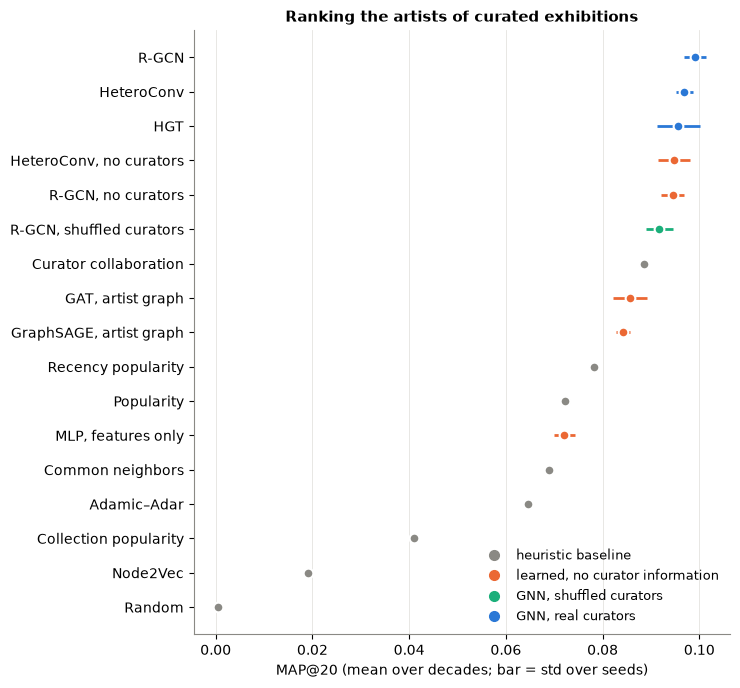

In [10]:
def dot_plot(mean, std, title, xlabel, path):
    order = mean["mean"].sort_values().index
    fig, ax = plt.subplots(figsize=(7.5, 0.34 * len(order) + 1.2))
    for y, tag in enumerate(order):
        color = FAMILY_COLORS[family(tag)]
        ax.errorbar(mean.loc[tag, "mean"], y, xerr=std.loc[tag, "mean"], fmt="o", ms=7,
                    color=color, ecolor=color, elinewidth=2, capsize=0, mec="white", mew=1.5)
    ax.set_yticks(range(len(order)), [LABELS.get(t, t) for t in order])
    ax.set(xlabel=xlabel, title=title)
    ax.grid(axis="y", visible=False)
    present = {family(t) for t in order}
    handles = [plt.Line2D([], [], marker="o", ls="", color=c, ms=7, label=f)
               for f, c in FAMILY_COLORS.items() if f in present]
    ax.legend(handles=handles, loc="lower right", frameon=False, fontsize=9)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()


dot_plot(main_mean, main_std, "Ranking the artists of curated exhibitions",
         "MAP@20 (mean over decades; bar = std over seeds)", OUT / "main_map20.png")

## 2. Curator ablations

Each row is a paired bootstrap over test exhibitions: the same exhibitions are scored by model A
and model B, and the exhibitions are resampled 1,000 times. GNN results are first averaged over
seeds per exhibition. A 95% CI entirely above 0 means A ranks better than B beyond sampling noise.
"pooled" resamples the exhibitions of all four decades together.

- **R-GCN / HeteroConv with vs without curators**: the research question, for two architectures.
- **Real vs shuffled curators**: do *who curated what* matter, or only the extra connectivity?
- **Curator collaboration vs popularity**: the same question for transparent heuristics.
- **Exhibition nodes vs artist-only graph**: does modeling exhibitions as nodes help, without
  curators?
- **Graph vs features only**: does message passing add anything over an MLP on the same features?
- **R-GCN vs curator collaboration**: does the GNN beat the best heuristic?

In [11]:
COMPARISONS = [
    ("rgcn_full", "rgcn_none", "R-GCN: curators vs none"),
    ("heteroconv_full", "heteroconv_none", "HeteroConv: curators vs none"),
    ("rgcn_full", "rgcn_shuffled", "R-GCN: real vs shuffled curators"),
    ("curator_collab", "popularity", "Heuristic: curator collaboration vs popularity"),
    ("rgcn_none", "sage_none", "Exhibition nodes vs artist-only graph"),
    ("rgcn_none", "mlp_none", "Graph vs features only (no curators)"),
    ("rgcn_full", "curator_collab", "R-GCN vs curator collaboration"),
    ("heteroconv_full", "curator_collab", "HeteroConv vs curator collaboration"),
]


def paired_values(a, b, metric="map@20", kind="per_exh"):
    frames = []
    for cutoff in CUTOFFS:
        (ra, _), (rb, _) = load_per_exh(a, cutoff, kind), load_per_exh(b, cutoff, kind)
        if ra is not None and rb is not None:
            frames.append(ra[[metric]].add_suffix("_a").join(rb[[metric]].add_suffix("_b"),
                                                               how="inner").assign(cutoff=cutoff))
    return pd.concat(frames) if frames else None


def ablation_table(comparisons, metric="map@20", kind="per_exh"):
    rows = []
    for a, b, label in comparisons:
        pairs = paired_values(a, b, metric, kind)
        if pairs is None:
            continue
        for cutoff, sub in [*pairs.groupby("cutoff"), ("pooled", pairs)]:
            res = paired_bootstrap(sub[f"{metric}_a"], sub[f"{metric}_b"])
            rows.append({"comparison": label, "cutoff": cutoff, "A": sub[f"{metric}_a"].mean(),
                         "B": sub[f"{metric}_b"].mean(), **res})
    return pd.DataFrame(rows)


ablations = ablation_table(COMPARISONS)
ablations.to_csv(OUT / "ablations_map20.csv", index=False)
ablations.round(4)

,comparison,cutoff,A,B,mean_diff,ci_low,ci_high,n,p_le_0
0,R-GCN: curators vs none,1950,0.0901,0.0928,-0.0027,-0.0092,0.0040,131,0.785
1,R-GCN: curators vs none,1960,0.0927,0.0913,0.0014,-0.0053,0.0088,163,0.350
2,R-GCN: curators vs none,1970,0.0925,0.0868,0.0057,-0.0015,0.0125,248,0.067
3,R-GCN: curators vs none,1980,0.1209,0.1072,0.0137,0.0001,0.0266,206,0.025
4,R-GCN: curators vs none,pooled,0.0999,0.0944,0.0055,0.0011,0.0103,748,0.012
5,HeteroConv: curators vs none,1950,0.0933,0.0916,0.0017,-0.0072,0.0101,131,0.400
6,HeteroConv: curators vs none,1960,0.0958,0.1026,-0.0068,-0.0153,0.0032,163,0.914
7,HeteroConv: curators vs none,1970,0.0871,0.0847,0.0024,-0.0062,0.0111,248,0.265
8,HeteroConv: curators vs none,1980,0.1114,0.1003,0.0111,-0.0008,0.0261,206,0.039
9,HeteroConv: curators vs none,pooled,0.0968,0.0941,0.0027,-0.0025,0.0082,748,0.166


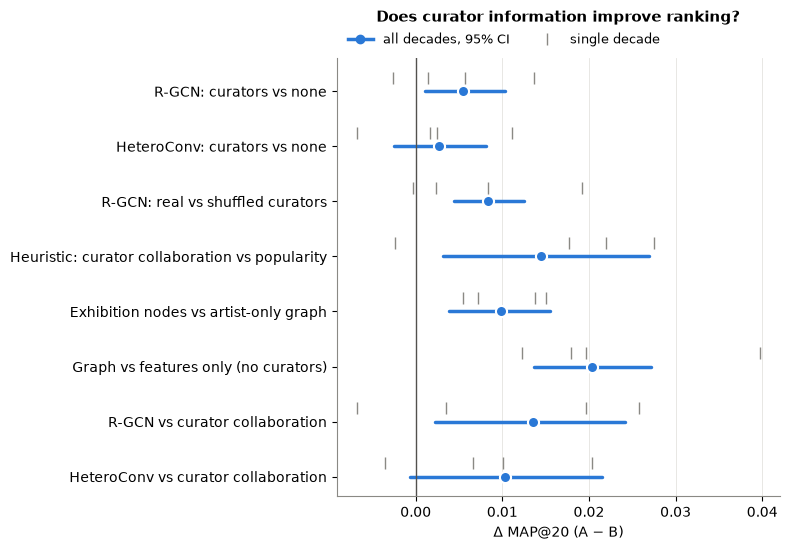

In [12]:
def forest_plot(table, title, xlabel, path):
    labels = list(dict.fromkeys(table["comparison"]))
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(labels) + 1.2))
    for y, label in enumerate(reversed(labels)):
        rows = table[table["comparison"] == label]
        pooled = rows[rows["cutoff"] == "pooled"].iloc[0]
        decades = rows[rows["cutoff"] != "pooled"]
        ax.plot([pooled["ci_low"], pooled["ci_high"]], [y, y], color="#2a78d6", lw=2.5,
                solid_capstyle="round")
        ax.plot(pooled["mean_diff"], y, "o", color="#2a78d6", ms=8, mec="white", mew=1.5)
        ax.plot(decades["mean_diff"], [y + 0.25] * len(decades), "|", color="#8a8984", ms=9)
    ax.axvline(0, color="#52514e", lw=1)
    ax.set_yticks(range(len(labels)), list(reversed(labels)))
    ax.xaxis.set_major_locator(plt.MaxNLocator(6))
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title, pad=26)
    ax.legend(handles=[
        plt.Line2D([], [], marker="o", color="#2a78d6", lw=2.5, label="all decades, 95% CI"),
        plt.Line2D([], [], marker="|", ls="", color="#8a8984", ms=9, label="single decade"),
    ], loc="lower left", bbox_to_anchor=(0, 1), ncol=2, frameon=False, fontsize=9)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()


forest_plot(ablations, "Does curator information improve ranking?", "Δ MAP@20 (A − B)",
            OUT / "ablations_map20.png")

## 3. Subgroups: whom does curator information help?

The unit is one (exhibition, artist) pair where the artist really exhibited. Its "hit" is whether
the model ranked that artist in the top 50 candidates (about the size of a mid-sized show's
shortlist), averaged over seeds. Groups:

- **experience**: established (3+ MoMA exhibitions before the cutoff) vs emerging (1–2);
- **gender** and **nationality region**, as recorded by MoMA (often missing; "unknown" is kept).

Δ is the hit-rate difference between the model with and without curator information. The CI
resamples exhibitions, because artists of the same show are correlated. These are differences in
*predictive information*, not causal effects of curators, and small groups are noisy.

In [13]:
REGIONS = {
    "Latin America": ["Mexican", "Argentine", "Brazilian", "Chilean", "Cuban", "Peruvian",
                      "Colombian", "Venezuelan", "Uruguayan", "Haitian", "Ecuadorian",
                      "Guatemalan", "Puerto Rican", "Bolivian", "Nicaraguan", "Panamanian",
                      "Costa Rican", "Dominican", "Salvadoran", "Paraguayan"],
    "Western Europe": ["French", "German", "British", "English", "Scottish", "Welsh", "Irish",
                       "Italian", "Swiss", "Dutch", "Spanish", "Austrian", "Belgian", "Swedish",
                       "Danish", "Finnish", "Norwegian", "Portuguese", "Icelandic", "Greek"],
    "Eastern Europe": ["Russian", "Polish", "Czech", "Hungarian", "Yugoslav", "Romanian",
                       "Bulgarian", "Ukrainian", "Latvian", "Lithuanian", "Estonian",
                       "Croatian", "Slovenian", "Serbian", "Czechoslovakian"],
}
REGION_OF = {"American": "United States"}
REGION_OF.update({n: r for r, ns in REGIONS.items() for n in ns})


def artist_groups(cutoff):
    a = data.artists
    begin = data.exhibitions["begin"]
    hist = data.artist_edges[begin.loc[data.artist_edges["exh_id"]].to_numpy() < year_start(cutoff)]
    n_prior = hist.groupby("artist").size().reindex(a.index, fill_value=0)
    region = a["nationality"].map(REGION_OF).fillna("other")
    return pd.DataFrame({
        "experience": np.where(n_prior >= 3, "established (3+ shows)", "emerging (1–2 shows)"),
        "gender": a["gender"],
        "region": region.where(a["nationality"] != "unknown", "unknown"),
    }, index=a.index)


def load_hits(tag, cutoff, k, kind="ranks"):
    """Hit@k of each positive pair of a curated exhibition, averaged over seeds."""
    files = result_files(tag, cutoff, kind)
    if not files:
        return None
    ranks = pd.concat([pd.read_csv(f) for f in files])
    ranks = ranks[data.exhibitions.loc[ranks["exh_id"], "has_curator"].to_numpy()]
    return (ranks["rank"] <= k).groupby([ranks["exh_id"], ranks["artist"]]).mean()


def cluster_bootstrap(pairs, n_boot=1000, seed=0):
    """95% CI of the mean pair difference, resampling whole exhibitions."""
    per = pairs.groupby("exh_id")["diff"].agg(["sum", "size"])
    idx = np.random.default_rng(seed).integers(0, len(per), size=(n_boot, len(per)))
    means = per["sum"].to_numpy()[idx].sum(1) / per["size"].to_numpy()[idx].sum(1)
    return np.quantile(means, [0.025, 0.975])


def subgroup_table(a, b, k=50, kind="ranks", min_pairs=30):
    frames = []
    for cutoff in CUTOFFS:
        ha, hb = load_hits(a, cutoff, k, kind), load_hits(b, cutoff, k, kind)
        if ha is not None and hb is not None:
            pairs = pd.DataFrame({"hit_a": ha, "hit_b": hb}).dropna().reset_index()
            frames.append(pairs.join(artist_groups(cutoff), on="artist"))
    pairs = pd.concat(frames, ignore_index=True)
    pairs["diff"] = pairs["hit_a"] - pairs["hit_b"]
    rows = []
    for dim in ["experience", "gender", "region"]:
        for group, sub in pairs.groupby(dim):
            if len(sub) < min_pairs:
                continue
            lo, hi = cluster_bootstrap(sub)
            rows.append({"dimension": dim, "group": group, "pairs": len(sub),
                         "exhibitions": sub["exh_id"].nunique(), f"hit@{k} A": sub["hit_a"].mean(),
                         f"hit@{k} B": sub["hit_b"].mean(), "delta": sub["diff"].mean(),
                         "ci_low": lo, "ci_high": hi})
    return pd.DataFrame(rows)


sub_gnn = subgroup_table("rgcn_full", "rgcn_none")
sub_heur = subgroup_table("curator_collab", "popularity")
sub_gnn.to_csv(OUT / "subgroups_rgcn.csv", index=False)
sub_heur.to_csv(OUT / "subgroups_heuristic.csv", index=False)
print("R-GCN with curators (A) vs without (B)")
display(sub_gnn.round(3))
print("Curator collaboration (A) vs popularity (B)")
display(sub_heur.round(3))

R-GCN with curators (A) vs without (B)


,dimension,group,pairs,exhibitions,hit@50 A,hit@50 B,delta,ci_low,ci_high
0,experience,emerging (1–2 shows),2579,439,0.027,0.024,0.003,-0.002,0.007
1,experience,established (3+ shows),8091,666,0.314,0.306,0.008,0.001,0.016
2,gender,female,770,277,0.076,0.070,0.005,-0.006,0.017
3,gender,male,9455,719,0.268,0.261,0.008,0.002,0.015
4,gender,unknown,445,116,0.033,0.040,-0.007,-0.014,0.003
5,region,Eastern Europe,306,110,0.035,0.037,-0.001,-0.013,0.010
6,region,Latin America,282,110,0.109,0.104,0.004,-0.015,0.024
7,region,United States,5210,553,0.222,0.217,0.006,-0.003,0.015
8,region,Western Europe,4324,460,0.311,0.302,0.009,-0.002,0.019
9,region,other,97,50,0.029,0.047,-0.019,-0.049,0.010


Curator collaboration (A) vs popularity (B)


,dimension,group,pairs,exhibitions,hit@50 A,hit@50 B,delta,ci_low,ci_high
0,experience,emerging (1–2 shows),2579,439,0.027,0.000,0.027,0.019,0.036
1,experience,established (3+ shows),8091,666,0.295,0.244,0.050,0.028,0.073
2,gender,female,770,277,0.155,0.000,0.155,0.119,0.195
3,gender,male,9455,719,0.243,0.209,0.034,0.016,0.052
4,gender,unknown,445,116,0.083,0.000,0.083,0.043,0.127
5,region,Eastern Europe,306,110,0.085,0.000,0.085,0.008,0.174
6,region,Latin America,282,110,0.110,0.089,0.021,-0.024,0.070
7,region,United States,5210,553,0.200,0.098,0.102,0.078,0.127
8,region,Western Europe,4324,460,0.299,0.333,-0.035,-0.060,-0.011
9,region,other,97,50,0.072,0.000,0.072,0.028,0.120


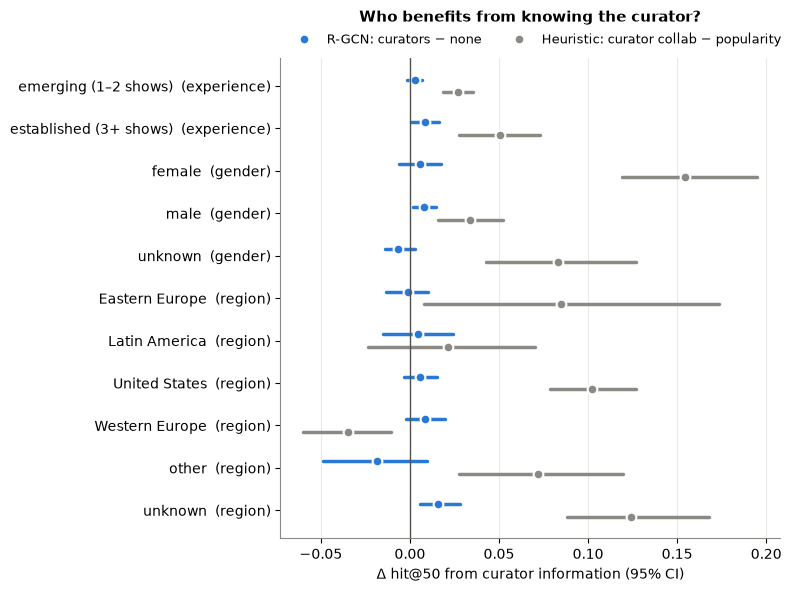

In [14]:
def subgroup_plot(tables, path, k=50):
    keys = list(dict.fromkeys(zip(tables[0][1]["dimension"], tables[0][1]["group"])))
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(keys) + 1.4))
    colors = ["#2a78d6", "#8a8984"]
    for j, (name, t) in enumerate(tables):
        t = t.set_index(["dimension", "group"])
        for y, key in enumerate(reversed(keys)):
            if key not in t.index:
                continue
            r = t.loc[key]
            yy = y + (0.15 if j == 0 else -0.15)
            ax.plot([r["ci_low"], r["ci_high"]], [yy, yy], color=colors[j], lw=2.5,
                    solid_capstyle="round")
            ax.plot(r["delta"], yy, "o", color=colors[j], ms=7, mec="white", mew=1.5,
                    label=name if y == 0 else None)
    ax.axvline(0, color="#52514e", lw=1)
    ax.set_yticks(range(len(keys)), [f"{g}  ({d})" for d, g in reversed(keys)])
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(f"Δ hit@{k} from curator information (95% CI)")
    ax.set_title("Who benefits from knowing the curator?", pad=26)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2, frameon=False, fontsize=9)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()


subgroup_plot([("R-GCN: curators − none", sub_gnn),
               ("Heuristic: curator collab − popularity", sub_heur)], OUT / "subgroups.png")

## 4. Cold start: debuting artists

Here each curated test exhibition ranks only the artists who make their MoMA debut in that
decade. The pool is known in advance (an optimistic, oracle assumption), but not which show each
artist debuts in. Every history-based score is 0 for these artists, so popularity reduces to
random. The learned models see their attributes (gender, nationality, birth year), how many of
their works MoMA had already acquired, and the exhibition's title, date and (for curator-aware
models) curators. They were trained only on returning artists, so this is a zero-shot transfer.

In [15]:
cold = runs[(runs["eval"] == "cold") & (runs["subset"] == "curated")]
cold_table, cold_mean, cold_std = results_table(cold)
cold_table.to_csv(OUT / "cold_start_map20.csv")
display(cold_table)
cold_ablations = ablation_table([
    ("rgcn_full", "rgcn_none", "R-GCN: curators vs none"),
    ("curator_profile", "demographic_popularity", "Heuristic: curator profile vs demographics"),
    ("rgcn_full", "mlp_none", "R-GCN vs feature-only MLP"),
    ("mlp_none", "collection_popularity", "Feature-only MLP vs collection popularity"),
    ("collection_popularity", "random", "Collection popularity vs random"),
    ("demographic_popularity", "random", "Demographic popularity vs random"),
], kind="cold_per_exh")
cold_ablations.to_csv(OUT / "cold_start_ablations.csv", index=False)
cold_ablations[cold_ablations["cutoff"] == "pooled"].round(4)

cutoff,seeds,1950,1960,1970,1980,mean
model,,,,,,
Random,1,0.003 ± 0.000,0.003 ± 0.000,0.003 ± 0.000,0.006 ± 0.000,0.004 ± 0.000
Collection popularity,1,0.007 ± 0.000,0.004 ± 0.000,0.004 ± 0.000,0.008 ± 0.000,0.006 ± 0.000
Demographic popularity,1,0.001 ± 0.000,0.002 ± 0.000,0.008 ± 0.000,0.006 ± 0.000,0.004 ± 0.000
Curator profile,1,0.003 ± 0.000,0.006 ± 0.000,0.009 ± 0.000,0.007 ± 0.000,0.006 ± 0.000
"MLP, features only",3,0.013 ± 0.004,0.006 ± 0.001,0.005 ± 0.002,0.010 ± 0.000,0.008 ± 0.002
"GraphSAGE, artist graph",3,0.011 ± 0.004,0.006 ± 0.001,0.009 ± 0.001,0.010 ± 0.001,0.009 ± 0.001
"GAT, artist graph",3,0.009 ± 0.008,0.007 ± 0.001,0.006 ± 0.002,0.006 ± 0.001,0.007 ± 0.001
"R-GCN, no curators",5,0.012 ± 0.001,0.006 ± 0.001,0.006 ± 0.002,0.014 ± 0.003,0.010 ± 0.001
"HeteroConv, no curators",3,0.008 ± 0.001,0.008 ± 0.002,0.008 ± 0.002,0.009 ± 0.002,0.008 ± 0.001


,comparison,cutoff,A,B,mean_diff,ci_low,ci_high,n,p_le_0
4,R-GCN: curators vs none,pooled,0.0101,0.0093,0.0008,-0.0008,0.0030,586,0.183
9,Heuristic: curator profile vs demographics,pooled,0.0068,0.0053,0.0015,0.0000,0.0032,586,0.023
14,R-GCN vs feature-only MLP,pooled,0.0101,0.0078,0.0024,0.0003,0.0047,586,0.010
19,Feature-only MLP vs collection popularity,pooled,0.0078,0.0055,0.0023,-0.0006,0.0056,586,0.059
24,Collection popularity vs random,pooled,0.0055,0.0037,0.0018,-0.0008,0.0043,586,0.083
29,Demographic popularity vs random,pooled,0.0053,0.0037,0.0016,-0.0014,0.0056,586,0.195


## 5. Limitations

**Uncurated exhibitions.** About a third of exhibitions have no recorded curator. For them the
"full" and "none" models see the same inputs about the target, so any gap there can only come
from how curators reshape the rest of the graph. That makes it a useful placebo check.

**Coverage over time.** Curator records get denser in later decades. If curator information
matters, the gain should be larger where curators are recorded more often.

In [16]:
# MAP@20 averaged over decades, then seeds.
placebo = (runs[(runs["eval"] == "main") & runs["subset"].isin(["curated", "uncurated"])]
           .groupby(["model", "subset", "seed"])["map@20"].mean()
           .groupby(["model", "subset"]).mean().unstack())
counts = runs[(runs["model"] == "popularity") & (runs["eval"] == "main")].groupby("subset")[
    "n_exhibitions"].sum()
print(f"{counts['curated']} curated and {counts['uncurated']} uncurated test exhibitions")
placebo.loc[model_order(placebo.index)].rename(index=LABELS).round(4)

748 curated and 189 uncurated test exhibitions


subset,curated,uncurated
model,,
Random,0.0005,0.0006
Popularity,0.0723,0.0987
Recency popularity,0.0781,0.1012
Collection popularity,0.0410,0.0405
Common neighbors,0.0688,0.0987
Adamic–Adar,0.0645,0.0987
Node2Vec,0.0192,0.0987
Curator collaboration,0.0885,0.0987
"MLP, features only",0.0721,0.0925


In [17]:
ex = data.exhibitions
coverage = pd.DataFrame({
    "test decade": [f"{c}s" for c in CUTOFFS],
    "frac exhibitions with curator": [
        ex[(ex["begin"] >= year_start(c)) & (ex["begin"] < year_start(c + 10))]["has_curator"].mean()
        for c in CUTOFFS],
}, index=CUTOFFS)
for label in ["R-GCN: curators vs none", "Heuristic: curator collaboration vs popularity"]:
    rows = ablations[(ablations["comparison"] == label) & (ablations["cutoff"] != "pooled")]
    rows = rows.set_index(rows["cutoff"].astype(int))
    coverage[label + " Δ"] = rows["mean_diff"].map("{:+.4f}".format) + "  [" + rows[
        "ci_low"].map("{:+.3f}".format) + ", " + rows["ci_high"].map("{:+.3f}".format) + "]"
coverage.round(3)

,test decade,frac exhibitions with curator,R-GCN: curators vs none Δ,Heuristic: curator collaboration vs popularity Δ
1950,1950s,0.664,"-0.0027 [-0.009, +0.004]","+0.0220 [+0.001, +0.045]"
1960,1960s,0.721,"+0.0014 [-0.005, +0.009]","+0.0177 [-0.000, +0.041]"
1970,1970s,0.846,"+0.0057 [-0.001, +0.012]","-0.0023 [-0.025, +0.019]"
1980,1980s,0.846,"+0.0137 [+0.000, +0.027]","+0.0275 [+0.003, +0.052]"


## 6. Case studies

We average each true (exhibition, artist) pair's rank over seeds, for R-GCN with and without
curators. We then list the pairs that the curator-aware model puts in its top 50 and that gain
the most places from curator information: the cases where knowing the curator changes the
shortlist. For each case, "shared shows" counts the
artist's earlier MoMA exhibitions that one of this exhibition's curators also curated. That is
the curator → past exhibition → artist path a curator-aware model can follow.

In [18]:
CASE_CUTOFF = 1960


def mean_ranks(tag, cutoff):
    files = result_files(tag, cutoff, "ranks")
    if not files:
        return None
    r = pd.concat([pd.read_csv(f) for f in files])
    return r.groupby(["exh_id", "artist"]).agg(rank=("rank", "mean"), n_candidates=("n_candidates", "first"))


def shared_shows(artist, exh_id, cutoff):
    """The artist's pre-cutoff exhibitions curated by one of `exh_id`'s curators."""
    ce, ae, begin = data.curator_edges, data.artist_edges, data.exhibitions["begin"]
    curators = ce.loc[ce["exh_id"] == exh_id, "curator"]
    past = ae.loc[(ae["artist"] == artist), "exh_id"]
    past = past[begin.loc[past].to_numpy() < year_start(cutoff)]
    links = ce[ce["exh_id"].isin(past) & ce["curator"].isin(curators)]
    return links, curators.tolist()


def case_table(cutoff, n=10, top_k=50):
    full, none = mean_ranks("rgcn_full", cutoff), mean_ranks("rgcn_none", cutoff)
    both = full.join(none["rank"].rename("rank_none"), how="inner")
    both = both[data.exhibitions.loc[both.index.get_level_values(0), "has_curator"].to_numpy()]
    both["improvement"] = both["rank_none"] - both["rank"]
    rows = []
    shortlisted = both[both["rank"] <= top_k]
    for (e, a), r in shortlisted.sort_values("improvement", ascending=False).head(n).iterrows():
        links, curators = shared_shows(a, e, cutoff)
        rows.append({
            "artist": data.artists.loc[a, "name"], "exhibition": data.exhibitions.loc[e, "title"],
            "year": data.exhibitions.loc[e, "begin"].year,
            "curators": ", ".join(data.curators.loc[curators, "name"]),
            "rank without curators": round(r["rank_none"]), "rank with curators": round(r["rank"]),
            "shared shows": links["exh_id"].nunique(), "exh_id": e, "artist_id": a})
    return pd.DataFrame(rows), both


cases, case_ranks = case_table(CASE_CUTOFF)
cases.to_csv(OUT / f"case_studies_T{CASE_CUTOFF}.csv", index=False)
improved = (case_ranks["improvement"] > 0).mean()
print(f"T={CASE_CUTOFF}: curators improve the rank of {improved:.0%} of true pairs "
      f"(median change {case_ranks['improvement'].median():+.0f} places)")
cases.drop(columns=["exh_id", "artist_id"])

T=1960: curators improve the rank of 50% of true pairs (median change +0 places)


,artist,exhibition,year,curators,rank without curators,rank with curators,shared shows
0,Max Beckmann,Portraits from the Museum Collection,1960,William S. Lieberman,245,47,6
1,Helen Levitt,Ben Schultz Memorial Exhibition,1968,John Szarkowski,216,32,0
2,Amedeo Modigliani,Portraits from the Museum Collection,1960,William S. Lieberman,213,41,0
3,Constantin Brancusi,Portraits from the Museum Collection,1960,William S. Lieberman,192,25,1
4,Édouard Vuillard,Portraits from the Museum Collection,1960,William S. Lieberman,182,24,4
5,Alberto Giacometti,Portraits from the Museum Collection,1960,William S. Lieberman,163,31,3
6,Paul Klee,Portraits from the Museum Collection,1960,William S. Lieberman,138,16,8
7,Juan Gris,Portraits from the Museum Collection,1960,William S. Lieberman,137,22,2
8,Robert Frank,Ben Schultz Memorial Exhibition,1968,John Szarkowski,113,31,0
9,Marc Chagall,Portraits from the Museum Collection,1960,William S. Lieberman,88,9,4


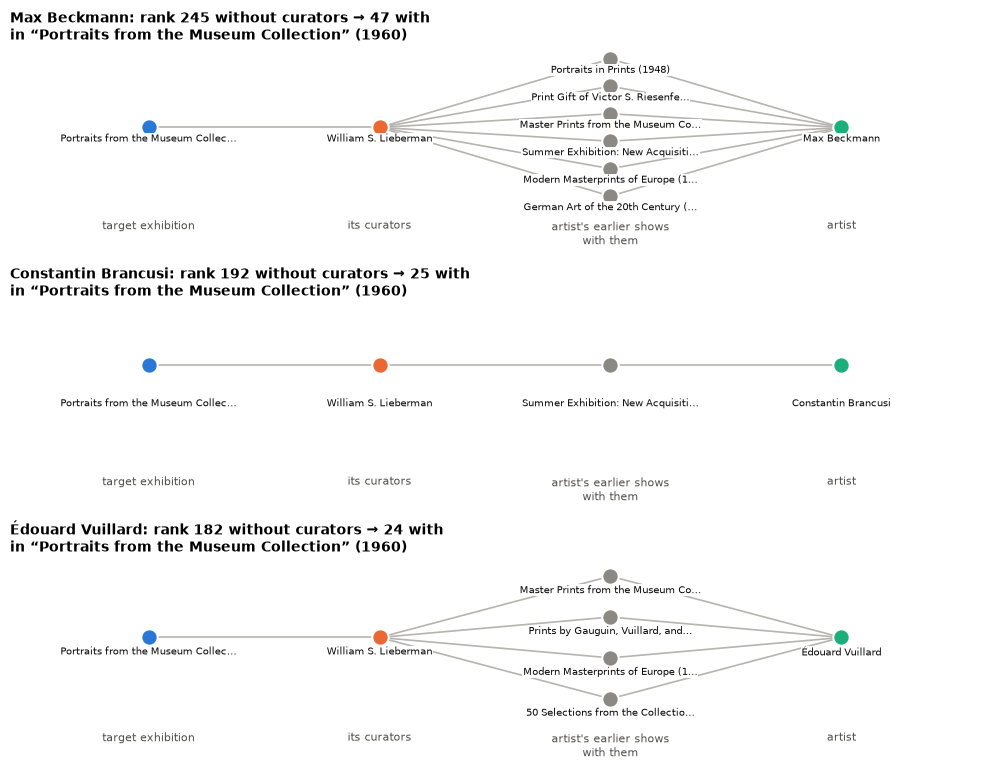

In [19]:
def ego_plot(ax, exh_id, artist, cutoff):
    """Target exhibition -> its curators -> the artist's earlier shows they curated -> artist."""
    links, curators = shared_shows(artist, exh_id, cutoff)
    shows = list(dict.fromkeys(links["exh_id"]))[:6]
    cols = {"exhibition": [exh_id], "curator": curators, "show": shows, "artist": [artist]}
    pos = {}
    for x, (kind, nodes) in enumerate(cols.items()):
        for i, node in enumerate(nodes):
            pos[(kind, node)] = (x, (len(nodes) - 1) / 2 - i)
    edges = [(("exhibition", exh_id), ("curator", c)) for c in curators]
    edges += [(("curator", c), ("show", s)) for c, s in zip(links["curator"], links["exh_id"])
              if s in shows]
    edges += [(("show", s), ("artist", artist)) for s in shows]
    for u, v in edges:
        ax.plot(*zip(pos[u], pos[v]), color="#b5b4ae", lw=1.2, zorder=1)
    style = {"exhibition": "#2a78d6", "curator": "#eb6834", "show": "#8a8984", "artist": "#1baf7a"}
    names = {"exhibition": lambda e: data.exhibitions.loc[e, "title"],
             "curator": lambda c: data.curators.loc[c, "name"],
             "show": lambda e: f"{data.exhibitions.loc[e, 'title']} ({data.exhibitions.loc[e, 'begin'].year})",
             "artist": lambda a: data.artists.loc[a, "name"]}
    for (kind, node), (x, y) in pos.items():
        ax.scatter(x, y, s=140, color=style[kind], edgecolor="white", linewidth=1.5, zorder=2)
        label = names[kind](node)
        label = label if len(label) <= 34 else label[:32] + "…"
        ax.text(x, y - 0.22, label, ha="center", va="top", fontsize=7.5, color="#0b0b0b",
                bbox=dict(fc="white", ec="none", pad=0.5), zorder=3)
    ax.set_xticks(range(4), ["target exhibition", "its curators", "artist's earlier shows\nwith them", "artist"])
    ax.tick_params(axis="x", length=0, labelsize=8, labelcolor="#52514e")
    ax.set_yticks([])
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_xlim(-0.6, 3.6)
    ys = [y for _, y in pos.values()]
    ax.set_ylim(min(ys) - 0.7, max(ys) + 0.4)


top = cases[cases["shared shows"] > 0].head(3)
if len(top):
    fig, axes = plt.subplots(len(top), 1, figsize=(10, 2.6 * len(top)))
    for ax, (_, c) in zip(np.atleast_1d(axes), top.iterrows()):
        ego_plot(ax, c["exh_id"], c["artist_id"], CASE_CUTOFF)
        title = c["exhibition"] if len(c["exhibition"]) <= 70 else \
            c["exhibition"][:68].rsplit(" ", 1)[0] + "…"
        ax.set_title(f"{c['artist']}: rank {c['rank without curators']} without curators → "
                     f"{c['rank with curators']} with\nin “{title}” ({c['year']})",
                     loc="left", fontsize=10)
    fig.tight_layout()
    fig.savefig(OUT / f"case_studies_T{CASE_CUTOFF}.png", dpi=150)
    plt.show()

### Test-time curator removal

`03_gnn` also takes one trained R-GCN (1960, seed 0), deletes a single test exhibition's curator
edges, and re-scores that exhibition with the same weights. Unlike the `none` ablation, which
trains a different model, this isolates how much this model's predictions lean on the curator
edges.

In [20]:
removal_files = sorted((RESULTS_DIR / "gnn").glob("curator_removal_*.csv"))
if removal_files:
    removal = pd.read_csv(removal_files[0])
    removal["change"] = removal["rank_without"] - removal["rank_with"]   # > 0: curators helped
    print(f"{removal_files[0].name}: {len(removal)} true pairs in {removal['exh_id'].nunique()} exhibitions")
    print(f"removing the curator edges worsens {(removal['change'] > 0).mean():.0%} of ranks, "
          f"improves {(removal['change'] < 0).mean():.0%}; median change {removal['change'].median():+.0f}")
    per_exh = removal.groupby("exh_id")["change"].median().sort_values(ascending=False)
    top_exh = per_exh.head(8).rename("median rank change").to_frame()
    top_exh["title"] = data.exhibitions.loc[top_exh.index, "title"]
    display(top_exh)
else:
    print("run the curator-removal cell in 03_gnn first")

curator_removal_rgcn_T1960_s0.csv: 2335 true pairs in 163 exhibitions
removing the curator edges worsens 49% of ranks, improves 44%; median change +0


,median rank change,title
exh_id,,
793,598.5,Harry Callahan and Robert Frank
985,556.0,Brassaï
848,386.0,Bonnard and His Environment
896,327.0,Turner: Imagination and Reality
939,301.5,Once Invisible
963,289.0,Manhattan Observed
853,236.0,André Kertész
890,217.0,Dorothea Lange


## 7. Findings

Numbers below are from the full grid (132 GNN runs) and are pooled over the 748 curated test
exhibitions of all four decades. If you re-run 02 or 03, check them against the tables above.

1. **Curator information helps R-GCN, a little.** MAP@20 rises from 0.094 to 0.100
   (Δ +0.0055, 95% CI [+0.001, +0.010]). The gain is concentrated in the 1970s and 1980s, the
   decades with the densest curator records (85% of exhibitions); in the 1950s and 1960s there is
   no difference. For HeteroConv the gain is smaller and not significant (Δ +0.0027,
   [−0.003, +0.008]).
2. **It matters *who* curated.** R-GCN with real curators beats R-GCN with curators shuffled
   within each decade (Δ +0.0084, [+0.004, +0.013]), and the shuffled model is no better than
   the one without curators. On *uncurated* exhibitions, however, the real and shuffled models
   both beat the no-curator model by about 0.007 (no CI computed). So part of the gain comes from
   curator nodes reshaping the graph in general; the real-vs-shuffled contrast on curated
   exhibitions is the cleaner evidence that the target's own curator carries information.
3. **The transparent heuristic agrees.** Ranking by past collaboration with the exhibition's
   curators beats popularity (Δ +0.0145, [+0.003, +0.027]), and the curator-aware R-GCN beats
   that heuristic (Δ +0.0135, [+0.002, +0.024]).
4. **Graph structure matters more than curators.** Without curators, the exhibition-node graph
   beats the artist-only co-exhibition graph (Δ +0.0098, [+0.004, +0.016]), and R-GCN beats a
   feature-only MLP (Δ +0.0204, [+0.014, +0.027]).
5. **Subgroups.** The R-GCN gain is small everywhere. It is significant for established artists
   and men, not for emerging artists or women. The curator heuristic, by contrast, moves women
   (hit@50 +0.155) and US artists (+0.10) up much more than popularity does, and moves Western
   Europeans down.
6. **Cold start is hard.** Ranking debuting artists, every model stays near MAP@20 = 0.01.
   R-GCN beats the feature-only MLP (Δ +0.0024, [+0.000, +0.005]), but curators add nothing
   significant (Δ +0.0008, [−0.001, +0.003]).
7. **Test-time removal** of curator edges from one trained 1960 model changes individual ranks in
   both directions (49% worse, 44% better, median 0), consistent with no curator effect in the
   1960s.

**Caveat.** The effect is small and depends on the setup. In tuning (validation, 1960 and 1970),
the model without curators scored highest, and an earlier configuration (2 layers, no learned
curator embeddings, no collection features; 5 seeds, run in PR #1) showed no curator
effect at all.